# 19 · Recommender Systems

"Because you watched…", "Customers also bought…", your social feed, your music radio: recommender systems decide much of what people see online. The task: given what we know about users and items, **predict what each user will like** and **rank** items for them.

**What you'll learn**
1. Explicit vs implicit feedback, the long tail, and why the data is **missing not at random**
2. Honest evaluation: time-based splits; **RMSE** for ratings; **precision@k, recall@k, NDCG@k**, coverage for rankings
3. Baselines: global mean, **user/item biases**, popularity
4. **Collaborative filtering:** item–item similarity
5. **Matrix factorisation:** 🐍 SGD in pure Python → 🔢 alternating least squares in NumPy → 📦 PyTorch
6. **Implicit feedback** and the **BPR** ranking loss
7. The **cold-start** problem and content-based hybrids
8. **Two-tower retrieval** with in-batch negatives — how large platforms recommend from millions of items
9. Pitfalls: popularity bias, feedback loops, offline vs online metrics

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math, random, time
import torch
from torch import nn
import torch.nn.functional as F
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0); torch.manual_seed(0); random.seed(0)

## 1. The data

We simulate a film-rating site, so that we know the ground truth. Each user and each film has hidden **taste factors** (think "likes action", "likes arthouse"…). A rating = overall average + user bias (some people rate everything high) + item bias (some films are just better) + **how well the user's taste matches the film**. Films belong to **genres**, which correlate with their factors. And, as on real platforms:
- **Popularity is long-tailed:** a few films get most of the ratings.
- **Missing not at random:** people mostly watch (and rate) films they expect to like.

In [2]:
def make_ratings(n_users=800, n_items=500, k=4, n_genres=6, seed=0):
    r = np.random.default_rng(seed)
    genre = r.integers(0, n_genres, n_items)
    genre_centre = r.normal(0, 1, (n_genres, k))
    V = genre_centre[genre] + r.normal(0, 0.5, (n_items, k))                   # item taste factors
    U = r.normal(0, 1, (n_users, k)) * 0.6                                      # user taste factors
    b_u, b_i = r.normal(0, 0.4, n_users), r.normal(0, 0.5, n_items)
    popularity = 1 / np.arange(1, n_items + 1) ** 0.8; r.shuffle(popularity)    # Zipf-like long tail
    rows = []
    for u in range(n_users):
        affinity = U[u] @ V.T
        p = popularity * np.exp(1.2 * affinity); p /= p.sum()                   # people pick what they expect to like
        items = r.choice(n_items, size=r.integers(15, 80), replace=False, p=p)
        t = np.sort(r.uniform(0, 365, len(items)))                              # days since launch
        for i, ts in zip(items, t):
            score = 3.4 + b_u[u] + b_i[i] + affinity[i] + r.normal(0, 0.5)
            rows.append((u, i, int(np.clip(np.round(score), 1, 5)), ts))
    df = pd.DataFrame(rows, columns=["user", "item", "rating", "day"])
    return df, genre, (U, V, b_u, b_i)

ratings, item_genre, truth = make_ratings()
n_users, n_items = ratings.user.nunique(), 500
print(f"{len(ratings):,} ratings from {n_users} users on {ratings.item.nunique()} items")
print(f"matrix density: {len(ratings) / (n_users * n_items):.1%} — {1 - len(ratings) / (n_users * n_items):.1%} of the user×item matrix is EMPTY")
ratings.head()

38,113 ratings from 800 users on 500 items
matrix density: 9.5% — 90.5% of the user×item matrix is EMPTY


,user,item,rating,day
0,0,36,5,9.871750
1,0,170,4,28.959573
2,0,334,5,67.317792
3,0,128,5,82.251535
4,0,26,5,85.487391


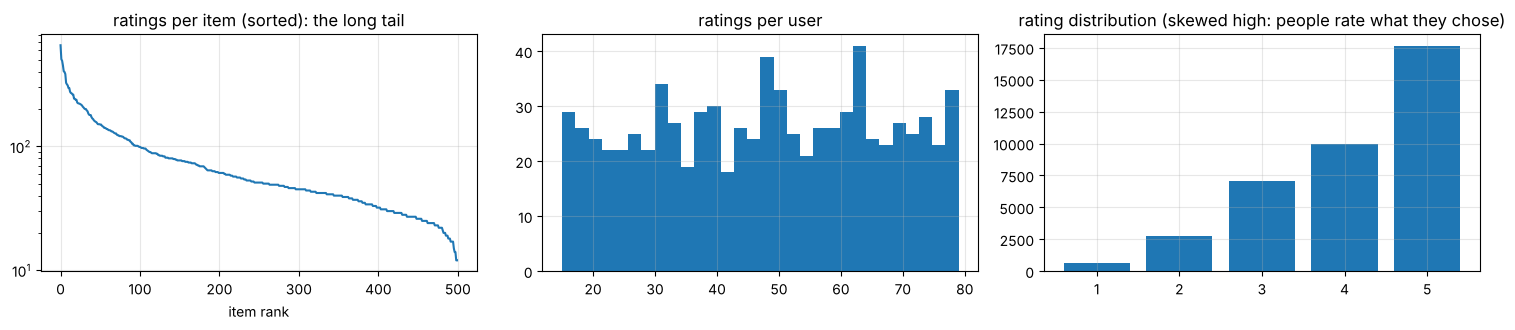

the top 20% of items receive 49% of all ratings


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
counts = ratings.item.value_counts().to_numpy()
ax[0].plot(counts); ax[0].set_title("ratings per item (sorted): the long tail"); ax[0].set_xlabel("item rank"); ax[0].set_yscale("log")
ax[1].hist(ratings.groupby("user").size(), bins=30); ax[1].set_title("ratings per user")
ax[2].bar(*np.unique(ratings.rating, return_counts=True)); ax[2].set_title("rating distribution (skewed high: people rate what they chose)")
plt.tight_layout(); plt.show()
top20 = counts[:int(0.2 * len(counts))].sum() / counts.sum()
print(f"the top 20% of items receive {top20:.0%} of all ratings")

**Explicit vs implicit feedback.** Star ratings are *explicit*, but rare. Most real systems learn from *implicit* signals: clicks, plays, purchases, watch time. Those are plentiful but only positive. A missing click might mean "didn't like it" or "never saw it". We'll do both.

## 2. Splitting and metrics

**Split by time:** for each user, hold out their **last 20%** of ratings. A random split would let the model use future behaviour to predict the past, the recommender version of leakage (notebook 03).

Two kinds of metrics:
- **Rating prediction:** RMSE between predicted and actual stars.
- **Ranking**, which is what users actually experience. Recommend the top k items the user hasn't rated yet, and count how many held-out items they actually liked (rating ≥ 4) appear:
  - **precision@k** = hits / k; **recall@k** = hits / (number of liked held-out items)
  - **NDCG@k**: rewards hits **near the top** of the list, $\sum_{\text{hits}} 1/\log_2(\text{rank} + 1)$, normalised by the best possible score
  - **coverage**: what fraction of the catalogue ever gets recommended (diversity)

In [4]:
ratings = ratings.sort_values(["user", "day"])
ratings["rank_in_user"] = ratings.groupby("user").cumcount()
ratings["n_user"] = ratings.groupby("user")["item"].transform("size")
is_test = ratings.rank_in_user >= (0.8 * ratings.n_user).astype(int)
train, test = ratings[~is_test].copy(), ratings[is_test].copy()
print(f"train {len(train):,} ratings, test {len(test):,} ratings")

R_train = np.zeros((n_users, n_items)); R_train[train.user, train.item] = train.rating      # 0 = unknown
seen = R_train > 0
test_liked = test[test.rating >= 4].groupby("user")["item"].apply(set).to_dict()

# 🐍 Pure Python ranking metrics
def precision_recall_ndcg_at_k(recommended, relevant, k):
    hits = [1 if item in relevant else 0 for item in recommended[:k]]
    dcg = sum(h / math.log2(i + 2) for i, h in enumerate(hits))
    idcg = sum(1 / math.log2(i + 2) for i in range(min(len(relevant), k)))
    return sum(hits) / k, sum(hits) / len(relevant), dcg / idcg if idcg else 0.0

def evaluate_ranking(score_matrix, k=10):
    """score_matrix: (users, items) — higher = recommend first. Already-seen items are excluded."""
    S = np.where(seen, -np.inf, score_matrix)
    top = np.argsort(-S, axis=1)[:, :k]
    P, R_, N = [], [], []
    for u, rel in test_liked.items():
        p, r, n = precision_recall_ndcg_at_k(top[u].tolist(), rel, k); P.append(p); R_.append(r); N.append(n)
    return {"precision@10": np.mean(P), "recall@10": np.mean(R_), "NDCG@10": np.mean(N), "coverage": len(np.unique(top)) / n_items}

def rmse(pred_fn):
    p = np.clip(pred_fn(test.user.to_numpy(), test.item.to_numpy()), 1, 5)
    return float(np.sqrt(np.mean((p - test.rating.to_numpy()) ** 2)))

results = {}

train 30,162 ratings, test 7,951 ratings


## 3. Baselines

- **Global mean:** predict the average rating for everything.
- **Bias model:** $\hat r_{ui} = \mu + b_u + b_i$ — "this user rates generously, this film is well-liked". Fitted with regularised alternating averages (shrink toward 0 for users/items with few ratings).
- **Popularity** (for ranking): recommend the most-rated items to everyone.

These are surprisingly strong. Always report them.

In [5]:
mu = train.rating.mean()

# 🐍 Pure Python bias model with shrinkage (λ acts like λ "virtual" ratings at the mean)
def fit_biases(df, mu, lam=5.0, iters=10):
    b_u = defaultdict_float(); b_i = defaultdict_float()
    by_user = df.groupby("user")[["item", "rating"]].apply(lambda g: list(zip(g.item, g.rating))).to_dict()
    by_item = df.groupby("item")[["user", "rating"]].apply(lambda g: list(zip(g.user, g.rating))).to_dict()
    for _ in range(iters):
        for i, lst in by_item.items(): b_i[i] = sum(r - mu - b_u[u] for u, r in lst) / (lam + len(lst))
        for u, lst in by_user.items(): b_u[u] = sum(r - mu - b_i[i] for i, r in lst) / (lam + len(lst))
    return b_u, b_i

from collections import defaultdict
def defaultdict_float(): return defaultdict(float)

b_u, b_i = fit_biases(train, mu)
bu_arr = np.array([b_u[u] for u in range(n_users)]); bi_arr = np.array([b_i[i] for i in range(n_items)])
results["global mean"] = {"RMSE": rmse(lambda u, i: np.full(len(u), mu))}
results["user + item biases"] = {"RMSE": rmse(lambda u, i: mu + bu_arr[u] + bi_arr[i])}
popularity = np.bincount(train.item, minlength=n_items).astype(float)
results["popularity"] = evaluate_ranking(np.tile(popularity, (n_users, 1)))
results["user + item biases"] |= evaluate_ranking(mu + bu_arr[:, None] + bi_arr[None, :])
pd.DataFrame(results).T.round(4)

,RMSE,precision@10,recall@10,NDCG@10,coverage
global mean,1.0699,NaN,NaN,NaN,NaN
user + item biases,0.8130,0.0247,0.0411,0.0351,0.034
popularity,NaN,0.0577,0.0820,0.0781,0.062


## 4. Collaborative filtering: item–item similarity

**"People who liked this also liked…"** Two items are similar if the **same users** rated them similarly. Represent each item by its column of (mean-centred) ratings and compare columns with **cosine similarity**. To score an unseen item for a user: a similarity-weighted average of the user's ratings on similar items they *have* rated.

No features about the films are needed — the pattern of who-liked-what is enough. That's the "collaborative" part.

In [6]:
# 🔢 NumPy item–item CF
centred = np.where(seen, R_train - (mu + bu_arr[:, None] + bi_arr[None, :]), 0.0)   # remove biases → residual tastes
norms = np.linalg.norm(centred, axis=0) + 1e-9
item_sim = (centred.T @ centred) / np.outer(norms, norms)                          # (items × items) cosine similarity
np.fill_diagonal(item_sim, 0)

def item_cf_scores(k_neighbours=30):
    sim = item_sim.copy()
    thresh = -np.sort(-sim, axis=1)[:, k_neighbours - 1:k_neighbours]               # keep each item's top-k neighbours
    sim[sim < thresh] = 0
    num = centred @ sim.T                                                            # Σ sim × residual rating
    den = np.abs(seen.astype(float) @ sim.T) + 1e-9
    return mu + bu_arr[:, None] + bi_arr[None, :] + num / den

S_cf = item_cf_scores()
results["item-item CF"] = {"RMSE": rmse(lambda u, i: S_cf[u, i])} | evaluate_ranking(S_cf)

nbrs = np.argsort(-item_sim, axis=1)[:, :10]
same_genre = np.mean(item_genre[nbrs] == item_genre[:, None])
print(f"share of each item's 10 most similar items that have the SAME genre: {same_genre:.1%} "
      f"(chance would be {np.mean(np.bincount(item_genre) ** 2) / len(item_genre) ** 2 * len(np.bincount(item_genre)):.1%})")
pd.DataFrame(results).T.round(4)

share of each item's 10 most similar items that have the SAME genre: 42.7% (chance would be 16.9%)


,RMSE,precision@10,recall@10,NDCG@10,coverage
global mean,1.0699,NaN,NaN,NaN,NaN
user + item biases,0.8130,0.0247,0.0411,0.0351,0.034
popularity,NaN,0.0577,0.0820,0.0781,0.062
item-item CF,0.7696,0.0215,0.0332,0.0260,0.760


Similar items share a genre far more often than chance would predict, which the model learned purely from ratings without ever being told the genres. The agreement isn't perfect, because the genres themselves overlap in taste space.

## 5. Matrix factorisation

The idea that won the Netflix Prize: approximate the (mostly empty) rating matrix as the product of two thin matrices — a k-dimensional vector $\mathbf{p}_u$ for each user and $\mathbf{q}_i$ for each item:
$$ \hat r_{ui} = \mu + b_u + b_i + \mathbf{p}_u \cdot \mathbf{q}_i $$
Fit by minimising squared error **on the observed ratings only**, plus L2 regularisation:
$$ \min \sum_{(u,i)\,\text{observed}} (r_{ui} - \hat r_{ui})^2 + \lambda\big(\|\mathbf{p}_u\|^2 + \|\mathbf{q}_i\|^2 + b_u^2 + b_i^2\big) $$
It's like the SVD of notebook 14 — but the matrix is 85% missing, so we can't just run SVD; we fit only the known entries. The learned factors are interpretable-ish "taste dimensions".

### 5.1 🐍 Stochastic gradient descent, pure Python

In [7]:
def mf_sgd_python(triples, n_users, n_items, k=8, lr=0.01, lam=0.05, epochs=15, seed=0):
    r = random.Random(seed)
    P = [[r.gauss(0, 0.1) for _ in range(k)] for _ in range(n_users)]
    Q = [[r.gauss(0, 0.1) for _ in range(k)] for _ in range(n_items)]
    bu, bi = [0.0] * n_users, [0.0] * n_items; mu_ = sum(t[2] for t in triples) / len(triples)
    triples = list(triples)
    for _ in range(epochs):
        r.shuffle(triples)
        for u, i, rating in triples:
            pred = mu_ + bu[u] + bi[i] + sum(P[u][f] * Q[i][f] for f in range(k))
            e = rating - pred
            bu[u] += lr * (e - lam * bu[u]); bi[i] += lr * (e - lam * bi[i])
            for f in range(k):
                pu, qi = P[u][f], Q[i][f]
                P[u][f] += lr * (e * qi - lam * pu); Q[i][f] += lr * (e * pu - lam * qi)
    return mu_, bu, bi, P, Q

t0 = time.perf_counter()
mu_s, bu_s, bi_s, P_s, Q_s = mf_sgd_python(list(zip(train.user, train.item, train.rating)), n_users, n_items)
P_s, Q_s, bu_s, bi_s = map(np.array, (P_s, Q_s, bu_s, bi_s))
S_sgd = mu_s + bu_s[:, None] + bi_s[None, :] + P_s @ Q_s.T
results["MF — SGD (pure Python)"] = {"RMSE": rmse(lambda u, i: S_sgd[u, i])} | evaluate_ranking(S_sgd)
print(f"trained in {time.perf_counter() - t0:.1f}s")

trained in 0.8s


### 5.2 🔢 Alternating least squares (ALS), NumPy
Fix all item vectors → each user's vector is a small **ridge regression** (closed form, notebook 01). Then fix users and solve for items. Alternate. Each step is exact, there's no learning rate, and every user (and item) can be solved in parallel — that's why ALS is used in big-data systems like Spark.

In [8]:
def mf_als(R, mask, k=8, lam=5.0, iters=12, seed=0):
    r = np.random.default_rng(seed); nu, ni = R.shape
    mu_ = R[mask].mean(); Rc = np.where(mask, R - mu_ - bu_arr[:, None] - bi_arr[None, :], 0)   # learn residuals after biases
    P = r.normal(0, 0.1, (nu, k)); Q = r.normal(0, 0.1, (ni, k)); I = lam * np.eye(k)
    losses = []
    for _ in range(iters):
        for u in range(nu):                                        # solve each user: (QᵀQ + λI) p = Qᵀ r
            idx = mask[u]; Qu = Q[idx]; P[u] = np.linalg.solve(Qu.T @ Qu + I, Qu.T @ Rc[u, idx])
        for i in range(ni):                                        # solve each item
            idx = mask[:, i]; Pi = P[idx]; Q[i] = np.linalg.solve(Pi.T @ Pi + I, Pi.T @ Rc[idx, i])
        losses.append(np.sqrt(np.mean((Rc - P @ Q.T)[mask] ** 2)))
    return mu_ + bu_arr[:, None] + bi_arr[None, :] + P @ Q.T, P, Q, losses

t0 = time.perf_counter()
S_als, P_als, Q_als, als_losses = mf_als(R_train, seen)
results["MF — ALS (NumPy)"] = {"RMSE": rmse(lambda u, i: S_als[u, i])} | evaluate_ranking(S_als)
print(f"ALS trained in {time.perf_counter() - t0:.1f}s; training RMSE per iteration: {np.round(als_losses[:5], 3)} …")

ALS trained in 0.2s; training RMSE per iteration: [0.708 0.603 0.574 0.563 0.555] …


### 5.3 📦 PyTorch — embeddings + any loss you like
In PyTorch, user and item vectors are just `nn.Embedding` tables. The same code extends to side features, deep models and ranking losses.

In [9]:
class MF(nn.Module):
    def __init__(self, n_users, n_items, k=8):
        super().__init__()
        self.P, self.Q = nn.Embedding(n_users, k), nn.Embedding(n_items, k)
        self.bu, self.bi = nn.Embedding(n_users, 1), nn.Embedding(n_items, 1)
        for e in (self.P, self.Q): nn.init.normal_(e.weight, 0, 0.1)
        for e in (self.bu, self.bi): nn.init.zeros_(e.weight)
        self.mu = nn.Parameter(torch.tensor(float(mu)))
    def forward(self, u, i):
        return self.mu + self.bu(u).squeeze(-1) + self.bi(i).squeeze(-1) + (self.P(u) * self.Q(i)).sum(-1)

u_t, i_t, r_t = (torch.tensor(train[c].to_numpy()) for c in ("user", "item", "rating"))
mf = MF(n_users, n_items); opt = torch.optim.Adam(mf.parameters(), lr=0.02)
for epoch in range(40):
    perm = torch.randperm(len(r_t))
    for s in range(0, len(r_t), 1024):
        b = perm[s:s + 1024]; pred = mf(u_t[b], i_t[b])
        loss = F.mse_loss(pred, r_t[b].float()) + 1e-3 * (mf.P(u_t[b]).pow(2).sum(-1) + mf.Q(i_t[b]).pow(2).sum(-1)).mean()
        opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    S_torch = mf(torch.arange(n_users).repeat_interleave(n_items), torch.arange(n_items).repeat(n_users)).reshape(n_users, n_items).numpy()
results["MF — PyTorch"] = {"RMSE": rmse(lambda u, i: S_torch[u, i])} | evaluate_ranking(S_torch)
pd.DataFrame(results).T.round(4)

,RMSE,precision@10,recall@10,NDCG@10,coverage
global mean,1.0699,NaN,NaN,NaN,NaN
user + item biases,0.8130,0.0247,0.0411,0.0351,0.034
popularity,NaN,0.0577,0.0820,0.0781,0.062
item-item CF,0.7696,0.0215,0.0332,0.0260,0.760
MF — SGD (pure Python),0.8026,0.0225,0.0399,0.0332,0.054
MF — ALS (NumPy),0.7328,0.0541,0.0844,0.0766,0.328
MF — PyTorch,0.7127,0.0397,0.0625,0.0469,0.806


**Reading the table: a classic surprise.**
- **For rating prediction, MF wins.** RMSE falls from 1.07 (global mean) to about 0.71 (PyTorch MF). The pure-Python SGD version is undertrained at 15 epochs; more epochs close the gap.
- **For ranking, popularity beats almost every rating-trained model.** These models learned to predict *how many stars you'd give if you watched*. They never learned *what you'll choose to watch*, because the training data contains only films people chose. A niche film that its few fans rate 5★ gets a high predicted rating, yet most users would never pick it.
- **Coverage tells the other side.** Popularity shows the same 6% of the catalogue to everyone. The personalised models spread their recommendations widely.

Low RMSE on *observed* ratings ≠ good recommendations. That's why the industry moved to training directly for ranking on **implicit** feedback:

## 6. Implicit feedback and BPR

With implicit data (clicks/plays), we only know positives. **Bayesian Personalised Ranking (BPR)** trains on **triples** (user, item they interacted with, random item they didn't), and pushes the positive's score above the negative's:
$$ \mathcal{L} = -\sum \log \sigma\big(\hat x_{u,i^+} - \hat x_{u,i^-}\big) + \lambda\|\Theta\|^2 $$
It optimises the *order* directly — a smooth proxy for AUC.

In [10]:
pos_u, pos_i = torch.tensor(train.user.to_numpy()), torch.tensor(train.item.to_numpy())    # "user interacted with item"
seen_t = torch.tensor(seen)

class BPR(nn.Module):
    def __init__(self, n_users, n_items, k=16):
        super().__init__(); self.P, self.Q = nn.Embedding(n_users, k), nn.Embedding(n_items, k); self.b = nn.Embedding(n_items, 1)
        nn.init.normal_(self.P.weight, 0, 0.1); nn.init.normal_(self.Q.weight, 0, 0.1); nn.init.zeros_(self.b.weight)
    def score(self, u, i): return (self.P(u) * self.Q(i)).sum(-1) + self.b(i).squeeze(-1)

bpr = BPR(n_users, n_items); opt = torch.optim.Adam(bpr.parameters(), lr=0.01)
for epoch in range(30):
    perm = torch.randperm(len(pos_u))
    for s in range(0, len(pos_u), 1024):
        b = perm[s:s + 1024]; u, ip = pos_u[b], pos_i[b]
        ineg = torch.randint(0, n_items, (len(b),))                                  # random negatives
        loss = -F.logsigmoid(bpr.score(u, ip) - bpr.score(u, ineg)).mean() + 1e-4 * (bpr.P(u).pow(2).sum() + bpr.Q(ip).pow(2).sum()) / len(b)
        opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    S_bpr = (bpr.P.weight @ bpr.Q.weight.T + bpr.b.weight.T).numpy()
results["BPR (implicit, ranking loss)"] = evaluate_ranking(S_bpr)
pd.DataFrame(results).T.round(4)

,RMSE,precision@10,recall@10,NDCG@10,coverage
global mean,1.0699,NaN,NaN,NaN,NaN
user + item biases,0.8130,0.0247,0.0411,0.0351,0.034
popularity,NaN,0.0577,0.0820,0.0781,0.062
item-item CF,0.7696,0.0215,0.0332,0.0260,0.760
MF — SGD (pure Python),0.8026,0.0225,0.0399,0.0332,0.054
MF — ALS (NumPy),0.7328,0.0541,0.0844,0.0766,0.328
MF — PyTorch,0.7127,0.0397,0.0625,0.0469,0.806
"BPR (implicit, ranking loss)",NaN,0.1085,0.1525,0.1468,0.956


BPR never saw a single star rating, only *which* items each user chose. Yet it ranks about **twice as well as popularity** and far better than every rating-trained model, with almost full catalogue coverage. Because the data is missing not at random, "what people choose to watch" carries most of the signal. This is why the industry runs on implicit feedback and ranking losses.

## 7. Cold start

A brand-new film has no ratings, so collaborative filtering knows nothing about it. A new user has no history. Remedies:
- **Content features:** genre, description text, image embeddings, price… → predict where a new item sits in the embedding space.
- **Popularity / trending** fallback for new users; ask a few onboarding questions; use context (device, location, time).
- **Exploration:** give new items some exposure (bandits, notebook 18) to collect data.

Below: learn a map from **genre** → item embedding on existing items, and use it to place "new" items we hold out entirely.

In [11]:
from sklearn.linear_model import Ridge
genre_onehot = np.eye(item_genre.max() + 1)[item_genre]
new_items = rng.choice(n_items, 50, replace=False)                    # pretend these 50 have never been rated
old = np.setdiff1d(np.arange(n_items), new_items)
mapper = Ridge(1.0).fit(genre_onehot[old], Q_als[old])                 # genre → ALS item factors
Q_cold = Q_als.copy(); Q_cold[new_items] = mapper.predict(genre_onehot[new_items])

def hit_rate_on_new_items(Q_used, use_bias):
    S = P_als @ Q_used.T + (bi_arr if use_bias else 0)
    S = np.where(seen, -np.inf, S)
    # among ONLY the new items, does the user's held-out liked new item rank in their top 5?
    hits = tot = 0
    for u, rel in test_liked.items():
        rel_new = rel & set(new_items.tolist())
        if not rel_new: continue
        top = new_items[np.argsort(-S[u, new_items])[:5]]
        hits += len(rel_new & set(top.tolist())) > 0; tot += 1
    return hits / tot

Q_rand = Q_als.copy(); Q_rand[new_items] = rng.normal(0, Q_als.std(), (50, Q_als.shape[1]))
print(f"hit rate@5 among cold items — random vectors: {hit_rate_on_new_items(Q_rand, False):.3f} | "
      f"genre-predicted vectors: {hit_rate_on_new_items(Q_cold, False):.3f} | true learned vectors (upper bound): {hit_rate_on_new_items(Q_als, False):.3f}")

hit rate@5 among cold items — random vectors: 0.158 | genre-predicted vectors: 0.398 | true learned vectors (upper bound): 0.406


Content features recover much of what collaborative filtering would learn, before a single rating exists. **Hybrid** recommenders combine both.

## 8. Two-tower retrieval — recommending from millions of items

Real platforms can't score every item for every user on each request. They use a **funnel**:
```
millions of items → candidate retrieval (fast, ~1000) → ranking model (accurate, ~100) → re-ranking for diversity/business rules → top 10
```
**Retrieval** uses a **two-tower** model: a *user tower* turns user features/history into a vector, an *item tower* turns item features into a vector, and relevance = their dot product. Item vectors are precomputed; at request time we compute one user vector and do an **approximate nearest-neighbour (ANN)** search (FAISS, ScaNN, HNSW) — milliseconds over millions of items.

Training with **in-batch negatives**: in a batch of (user, positive item) pairs, every *other* item in the batch is a negative. Softmax cross-entropy over the batch — a contrastive loss, like CLIP.

In [12]:
# User tower: average of the embeddings of items in the user's history (works for brand-new users too!)
hist = [train[train.user == u].item.to_numpy() for u in range(n_users)]
max_h = max(map(len, hist)); H = torch.zeros(n_users, max_h, dtype=torch.long); Hmask = torch.zeros(n_users, max_h)
for u, h in enumerate(hist): H[u, :len(h)] = torch.tensor(h); Hmask[u, :len(h)] = 1

class TwoTower(nn.Module):
    def __init__(self, n_items, n_genres, d=32):
        super().__init__()
        self.item_id = nn.Embedding(n_items, d); self.item_genre = nn.Embedding(n_genres, d)
        self.user_mlp = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, d))
        self.item_mlp = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, d))
        self.genres = torch.tensor(item_genre)
    def item_vec(self, items):
        return F.normalize(self.item_mlp(self.item_id(items) + self.item_genre(self.genres[items])), dim=-1)
    def user_vec(self, users):
        e = self.item_id(H[users]) * Hmask[users][..., None]
        return F.normalize(self.user_mlp(e.sum(1) / Hmask[users].sum(1, keepdim=True).clamp(min=1)), dim=-1)

tt = TwoTower(n_items, item_genre.max() + 1); opt = torch.optim.Adam(tt.parameters(), lr=3e-3); temperature = 0.1
for epoch in range(15):
    perm = torch.randperm(len(pos_u))
    for s in range(0, len(pos_u), 512):
        b = perm[s:s + 512]
        logits = tt.user_vec(pos_u[b]) @ tt.item_vec(pos_i[b]).T / temperature     # (batch × batch): diagonal = positives
        loss = F.cross_entropy(logits, torch.arange(len(b)))
        opt.zero_grad(); loss.backward(); opt.step()

with torch.no_grad():
    item_index = tt.item_vec(torch.arange(n_items)).numpy()                     # precomputed "index" of item vectors
    user_vecs = tt.user_vec(torch.arange(n_users)).numpy()
S_tt = user_vecs @ item_index.T                                               # brute-force nearest neighbours (ANN in production)
results["two-tower retrieval"] = evaluate_ranking(S_tt)
pd.DataFrame(results).T.round(4)

,RMSE,precision@10,recall@10,NDCG@10,coverage
global mean,1.0699,NaN,NaN,NaN,NaN
user + item biases,0.8130,0.0247,0.0411,0.0351,0.034
popularity,NaN,0.0577,0.0820,0.0781,0.062
item-item CF,0.7696,0.0215,0.0332,0.0260,0.760
MF — SGD (pure Python),0.8026,0.0225,0.0399,0.0332,0.054
MF — ALS (NumPy),0.7328,0.0541,0.0844,0.0766,0.328
MF — PyTorch,0.7127,0.0397,0.0625,0.0469,0.806
"BPR (implicit, ranking loss)",NaN,0.1085,0.1525,0.1468,0.956
two-tower retrieval,NaN,0.0561,0.0781,0.0697,0.982


In [13]:
# Retrieval recall: does the two-tower model's top-100 contain the user's liked held-out items?
# (In the funnel, retrieval only needs to get good items INTO the candidate set; the ranker orders them.)
for name, S in [("popularity", np.tile(popularity, (n_users, 1))), ("two-tower", S_tt), ("BPR", S_bpr)]:
    S_ = np.where(seen, -np.inf, S); top100 = np.argsort(-S_, axis=1)[:, :100]
    rec = np.mean([len(rel & set(top100[u].tolist())) / len(rel) for u, rel in test_liked.items()])
    print(f"{name:11s} recall@100 = {rec:.3f}")

popularity  recall@100 = 0.446
two-tower   recall@100 = 0.551
BPR         recall@100 = 0.637


On this small dataset, BPR beats our two-tower model. BPR learns a **free vector for every user**, which works well when every user has plenty of history and the user set never changes. The two-tower model's advantages are **structural** rather than raw accuracy here:
- It computes a user vector from features and history, so it can serve brand-new users (and new items, via the item tower's features) without retraining.
- It scales to catalogues of millions through ANN search.

In production, its job is **high recall@100** for the candidate set, with a heavier ranking model ordering the final list.

## 9. Pitfalls and real-world concerns
- **Popularity bias & feedback loops:** recommending popular items makes them more popular; the training data then reflects *what you showed*, not what users would have chosen. Mitigate with exploration, inverse-propensity weighting and diversity constraints.
- **Offline ≠ online:** offline metrics on logged data are biased toward the old system's choices. The final judge is an **A/B test** on engagement, retention or revenue (notebook 13).
- **Beyond accuracy:** diversity, novelty, serendipity, fairness to item providers, and avoiding filter bubbles.
- **Freshness:** tastes and catalogues change — retrain often; use recent interactions in the user tower.
- **Leakage:** split by time; don't let features computed on the test period into training.

## Key takeaways
- The user×item matrix is huge and ~all empty; data is missing-not-at-random and long-tailed.
- Evaluate with time-based splits and ranking metrics (precision/recall/NDCG@k, coverage), not just RMSE.
- Biases + popularity are strong baselines. Item-item CF uses co-rating patterns.
- Matrix factorisation learns user and item vectors; fit with SGD, ALS or PyTorch embeddings.
- Implicit feedback + ranking losses (BPR, in-batch softmax) are the industry standard.
- Cold start needs content features; large systems use a retrieval → ranking funnel with two-tower models and ANN search.

## Exercises
1. Vary the number of factors k in ALS (2, 4, 8, 16, 32). Plot test RMSE and NDCG@10. Where does it start to overfit?
2. Add **user-user** CF (similar users' ratings) and compare with item-item CF.
3. Re-rank each user's top-50 from MF to increase **genre diversity** (e.g. at most 3 items per genre in the top 10). How much NDCG do you lose, and how much coverage do you gain?
4. In BPR, sample negatives proportionally to popularity instead of uniformly. What happens to coverage?

In [14]:
# Exercise 1 — solution
rows = []
for k_ in [2, 4, 8, 16, 32]:
    S_k = mf_als(R_train, seen, k=k_, iters=8)[0]
    rows.append({"k": k_, "test RMSE": rmse(lambda u, i: S_k[u, i]), "NDCG@10": evaluate_ranking(S_k)["NDCG@10"]})
pd.DataFrame(rows).set_index("k").round(4)

,test RMSE,NDCG@10
k,,
2,0.7742,0.0610
4,0.7516,0.0682
8,0.7471,0.0747
16,0.7627,0.0693
32,0.7634,0.0670


**Next:** [20 · Graph Neural Networks](20_graph_neural_networks.ipynb) — learning on networks of connected things (users and items form one!).

*Going deeper / interview prep:* `ML_System_Design_Notes.md` Part 4 (the retrieval → ranking funnel, two-tower retrieval, ANN, re-ranking), §5.7 (feedback loops), §7.1 (feed ranking), §7.7 (new-item-heavy catalogue) · `ML_Interview_Notes.md` (recommendation metrics) · code: `ml_from_scratch_part2.py` → `MatrixFactorization`, `ItemBasedCF`.